In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("customer_shopping_behavior.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 3900
Columns: 18


In [5]:
print(df.columns.tolist())

['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [7]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [8]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print("Unique customers:", df["Customer ID"].nunique())
print("Categories:", df["Category"].unique())
print("Seasons:", df["Season"].unique())
print("Payment methods:", df["Payment Method"].unique())

Unique customers: 3900
Categories: ['Clothing' 'Footwear' 'Outerwear' 'Accessories']
Seasons: ['Winter' 'Spring' 'Summer' 'Fall']
Payment methods: ['Venmo' 'Cash' 'Credit Card' 'PayPal' 'Bank Transfer' 'Debit Card']


In [12]:
df["Review Rating"].mean()

np.float64(3.750064716541548)

In [14]:
df["Review Rating"] = df["Review Rating"].fillna(
    df["Review Rating"].median()
)

In [15]:
df["Review Rating"].isnull().sum()

np.int64(0)

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df["Age"].describe()

count    3900.000000
mean       44.068462
std        15.207589
min        18.000000
25%        31.000000
50%        44.000000
75%        57.000000
max        70.000000
Name: Age, dtype: float64

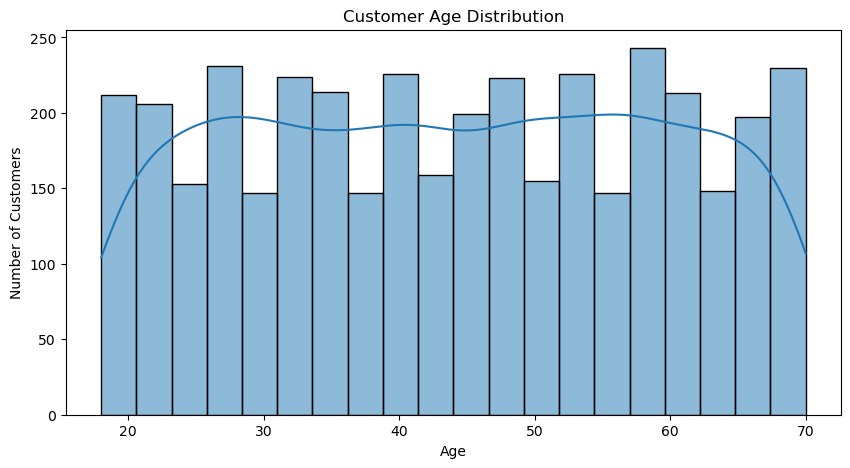

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Male      2652
Female    1248
Name: count, dtype: int64


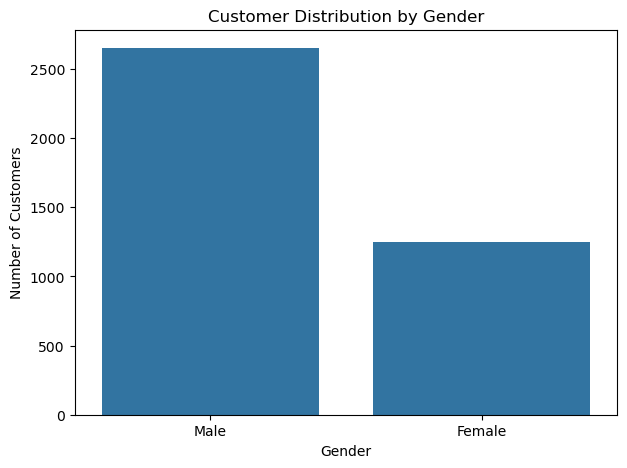

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
category_counts = df["Category"].value_counts()

print(category_counts)

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64


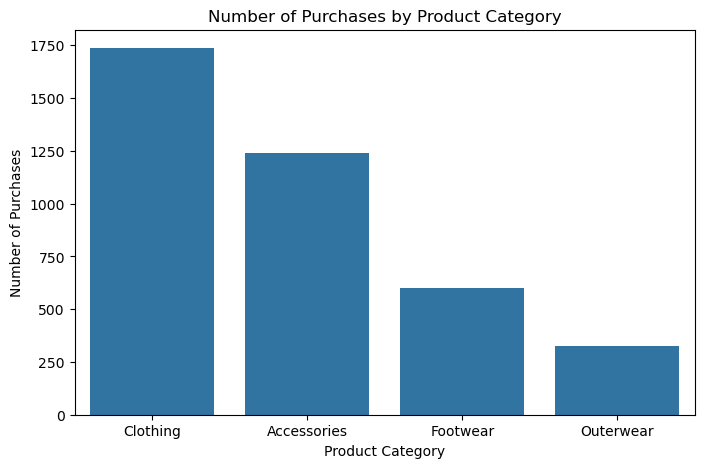

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Category",
    order=df["Category"].value_counts().index
)

plt.title("Number of Purchases by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Purchases")

plt.show()

In [24]:
category_sales = df.groupby("Category")["Purchase Amount (USD)"].sum().sort_values(ascending=False)

print(category_sales)

Category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: Purchase Amount (USD), dtype: int64


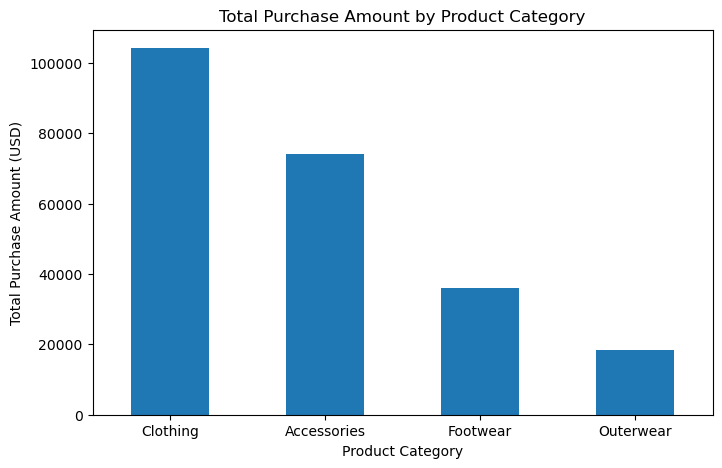

In [29]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Purchase Amount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Amount (USD)")

plt.xticks(rotation=0)
plt.show()

In [30]:
item_counts = df["Item Purchased"].value_counts()

print(item_counts)

Item Purchased
Blouse        171
Pants         171
Jewelry       171
Shirt         169
Dress         166
Sweater       164
Jacket        163
Coat          161
Sunglasses    161
Belt          161
Sandals       160
Socks         159
Skirt         158
Scarf         157
Shorts        157
Hat           154
Handbag       153
Hoodie        151
Shoes         150
T-shirt       147
Sneakers      145
Boots         144
Backpack      143
Gloves        140
Jeans         124
Name: count, dtype: int64


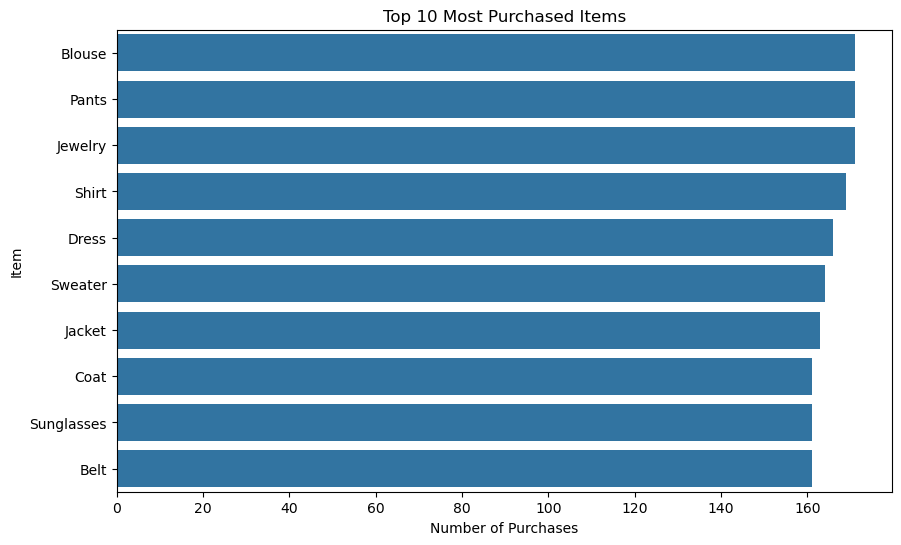

In [31]:
top_items = item_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_items.values,
    y=top_items.index
)

plt.title("Top 10 Most Purchased Items")
plt.xlabel("Number of Purchases")
plt.ylabel("Item")

plt.show()

In [32]:
df["Purchase Amount (USD)"].describe()

count    3900.000000
mean       59.764359
std        23.685392
min        20.000000
25%        39.000000
50%        60.000000
75%        81.000000
max       100.000000
Name: Purchase Amount (USD), dtype: float64

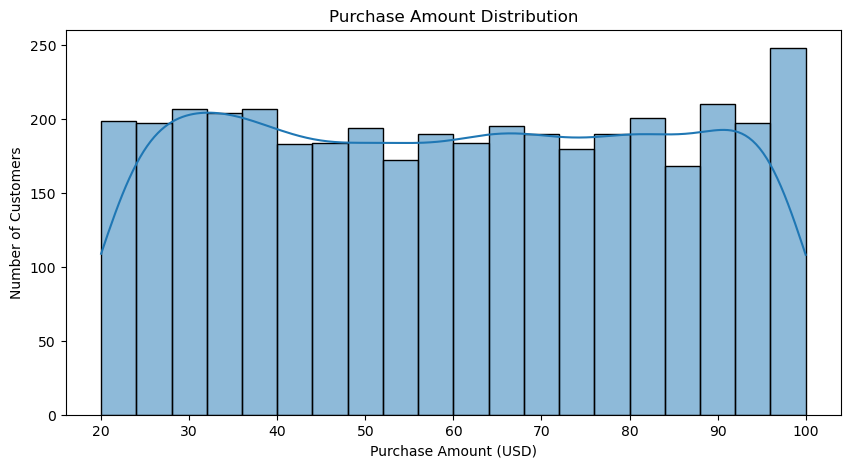

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Purchase Amount (USD)",
    bins=20,
    kde=True
)

plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Number of Customers")

plt.show()

In [34]:
avg_purchase_category = (
    df.groupby("Category")["Purchase Amount (USD)"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_purchase_category)

Category
Footwear       60.255426
Clothing       60.025331
Accessories    59.838710
Outerwear      57.172840
Name: Purchase Amount (USD), dtype: float64


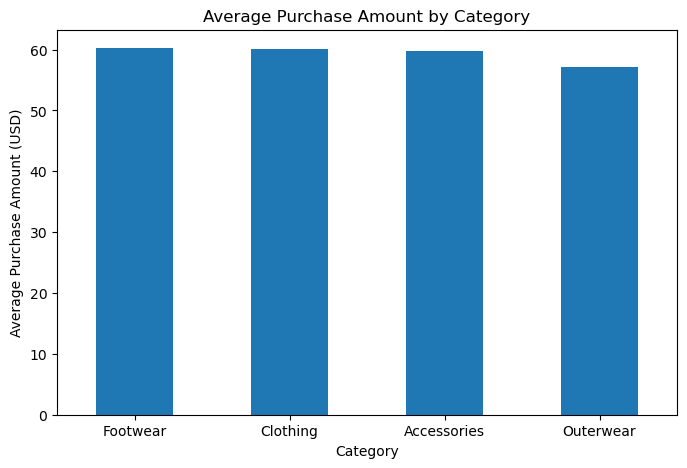

In [35]:
plt.figure(figsize=(8, 5))

avg_purchase_category.plot(kind="bar")

plt.title("Average Purchase Amount by Category")
plt.xlabel("Category")
plt.ylabel("Average Purchase Amount (USD)")

plt.xticks(rotation=0)
plt.show()

In [36]:
season_counts = df["Season"].value_counts()

print(season_counts)

Season
Spring    999
Fall      975
Winter    971
Summer    955
Name: count, dtype: int64


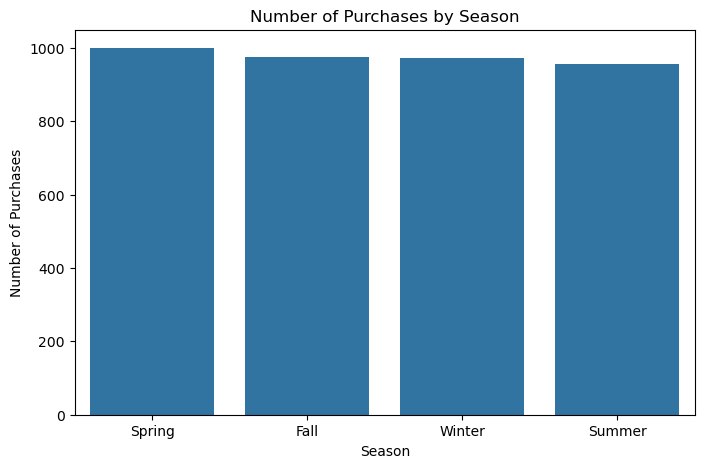

In [37]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Season",
    order=season_counts.index
)

plt.title("Number of Purchases by Season")
plt.xlabel("Season")
plt.ylabel("Number of Purchases")

plt.show()

In [38]:
season_sales = (
    df.groupby("Season")["Purchase Amount (USD)"]
    .sum()
    .sort_values(ascending=False)
)

print(season_sales)

Season
Fall      60018
Spring    58679
Winter    58607
Summer    55777
Name: Purchase Amount (USD), dtype: int64


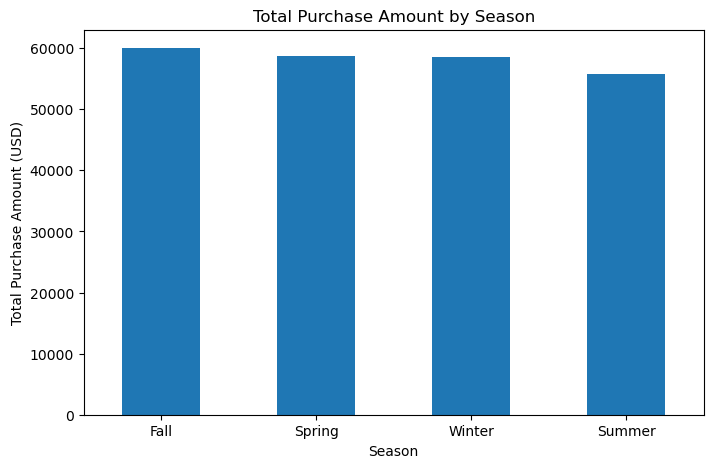

In [39]:
plt.figure(figsize=(8, 5))

season_sales.plot(kind="bar")

plt.title("Total Purchase Amount by Season")
plt.xlabel("Season")
plt.ylabel("Total Purchase Amount (USD)")

plt.xticks(rotation=0)
plt.show()

In [40]:
payment_counts = df["Payment Method"].value_counts()

print(payment_counts)

Payment Method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64


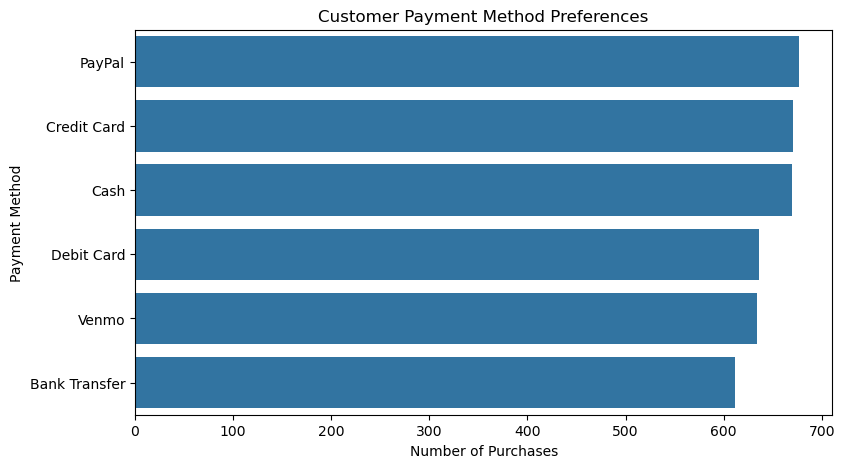

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_counts.values,
    y=payment_counts.index
)

plt.title("Customer Payment Method Preferences")
plt.xlabel("Number of Purchases")
plt.ylabel("Payment Method")

plt.show()

In [42]:
payment_sales = (
    df.groupby("Payment Method")["Purchase Amount (USD)"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_sales)

Payment Method
Credit Card      40310
PayPal           40109
Cash             40002
Debit Card       38742
Venmo            37374
Bank Transfer    36544
Name: Purchase Amount (USD), dtype: int64


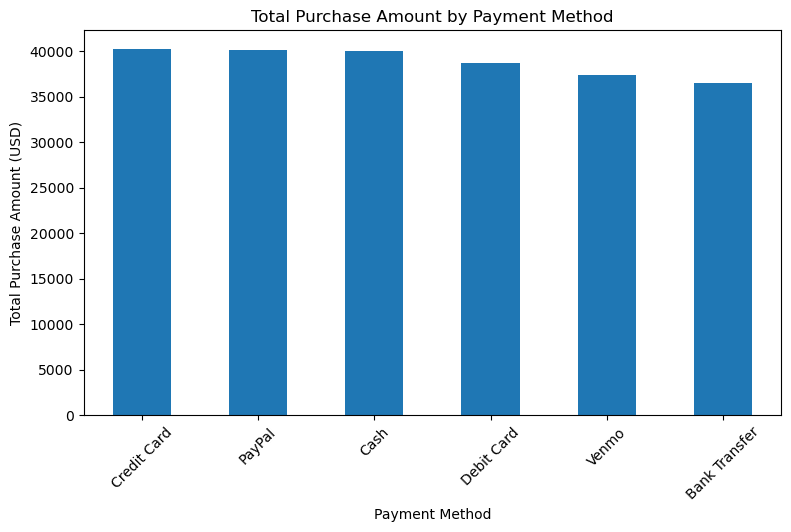

In [43]:
plt.figure(figsize=(9, 5))

payment_sales.plot(kind="bar")

plt.title("Total Purchase Amount by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Purchase Amount (USD)")

plt.xticks(rotation=45)
plt.show()

In [44]:
discount_counts = df["Discount Applied"].value_counts()

print(discount_counts)

Discount Applied
No     2223
Yes    1677
Name: count, dtype: int64


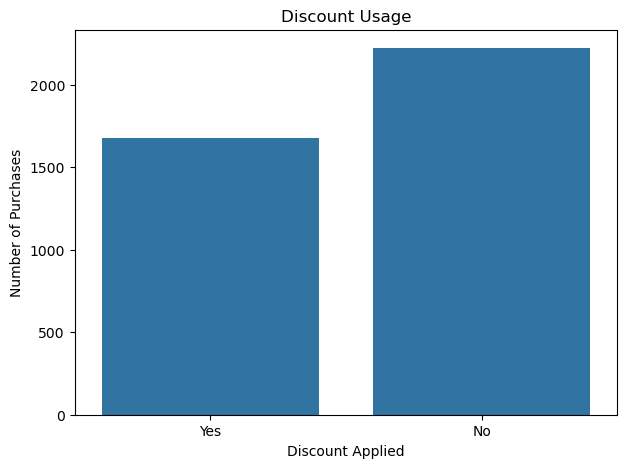

In [45]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Discount Applied"
)

plt.title("Discount Usage")
plt.xlabel("Discount Applied")
plt.ylabel("Number of Purchases")

plt.show()

In [46]:
discount_purchase = (
    df.groupby("Discount Applied")["Purchase Amount (USD)"]
    .mean()
)

print(discount_purchase)

Discount Applied
No     60.130454
Yes    59.279070
Name: Purchase Amount (USD), dtype: float64


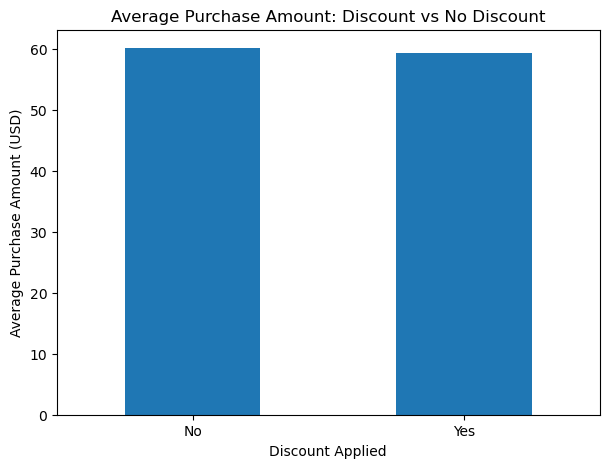

In [47]:
plt.figure(figsize=(7, 5))

discount_purchase.plot(kind="bar")

plt.title("Average Purchase Amount: Discount vs No Discount")
plt.xlabel("Discount Applied")
plt.ylabel("Average Purchase Amount (USD)")

plt.xticks(rotation=0)
plt.show()

In [48]:
promo_counts = df["Promo Code Used"].value_counts()

print(promo_counts)

Promo Code Used
No     2223
Yes    1677
Name: count, dtype: int64


In [49]:
df["Review Rating"].describe()

count    3900.000000
mean        3.750538
std         0.713589
min         2.500000
25%         3.100000
50%         3.800000
75%         4.400000
max         5.000000
Name: Review Rating, dtype: float64

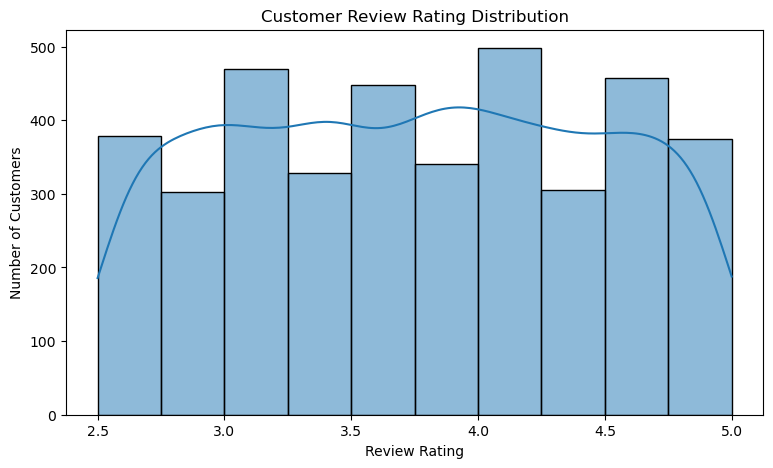

In [50]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Review Rating",
    bins=10,
    kde=True
)

plt.title("Customer Review Rating Distribution")
plt.xlabel("Review Rating")
plt.ylabel("Number of Customers")

plt.show()

In [51]:
category_rating = (
    df.groupby("Category")["Review Rating"]
    .mean()
    .sort_values(ascending=False)
)

print(category_rating)

Category
Footwear       3.793823
Accessories    3.770242
Outerwear      3.745988
Clothing       3.722395
Name: Review Rating, dtype: float64


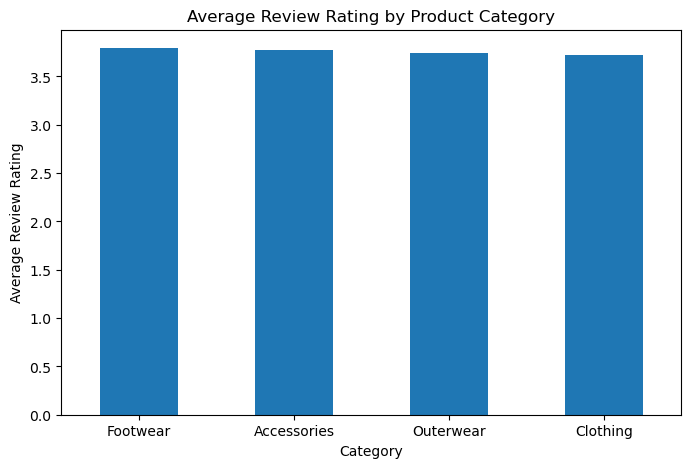

In [52]:
plt.figure(figsize=(8, 5))

category_rating.plot(kind="bar")

plt.title("Average Review Rating by Product Category")
plt.xlabel("Category")
plt.ylabel("Average Review Rating")

plt.xticks(rotation=0)
plt.show()

In [53]:
shipping_counts = df["Shipping Type"].value_counts()

print(shipping_counts)

Shipping Type
Free Shipping     675
Standard          654
Store Pickup      650
Next Day Air      648
Express           646
2-Day Shipping    627
Name: count, dtype: int64


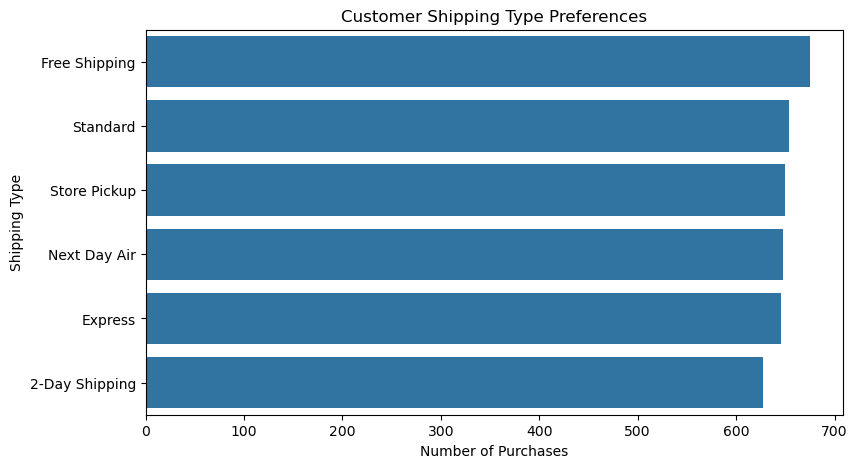

In [54]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=shipping_counts.values,
    y=shipping_counts.index
)

plt.title("Customer Shipping Type Preferences")
plt.xlabel("Number of Purchases")
plt.ylabel("Shipping Type")

plt.show()

In [55]:
shipping_spending = (
    df.groupby("Shipping Type")["Purchase Amount (USD)"]
    .mean()
    .sort_values(ascending=False)
)

print(shipping_spending)

Shipping Type
2-Day Shipping    60.733652
Express           60.475232
Free Shipping     60.410370
Store Pickup      59.893846
Next Day Air      58.631173
Standard          58.460245
Name: Purchase Amount (USD), dtype: float64


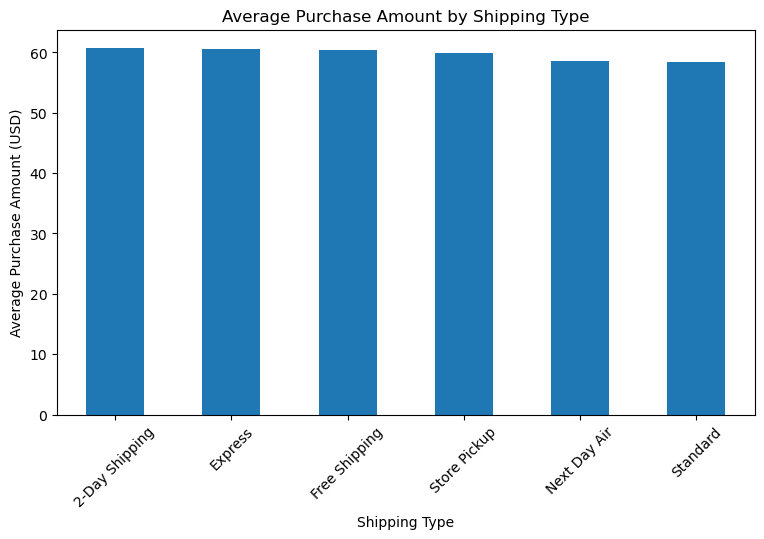

In [56]:
plt.figure(figsize=(9, 5))

shipping_spending.plot(kind="bar")

plt.title("Average Purchase Amount by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Average Purchase Amount (USD)")

plt.xticks(rotation=45)
plt.show()

In [57]:
numeric_cols = [
    "Age",
    "Purchase Amount (USD)",
    "Review Rating",
    "Previous Purchases"
]

correlation = df[numeric_cols].corr()

print(correlation)

                            Age  Purchase Amount (USD)  Review Rating  \
Age                    1.000000              -0.010424      -0.024263   
Purchase Amount (USD) -0.010424               1.000000       0.029902   
Review Rating         -0.024263               0.029902       1.000000   
Previous Purchases     0.040445               0.008063       0.003620   

                       Previous Purchases  
Age                              0.040445  
Purchase Amount (USD)            0.008063  
Review Rating                    0.003620  
Previous Purchases               1.000000  


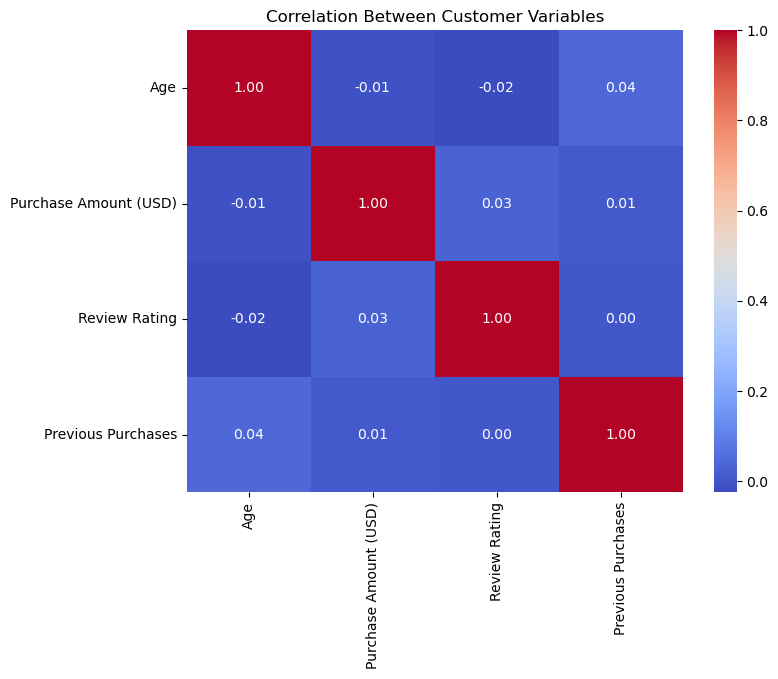

In [58]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Customer Variables")

plt.show()

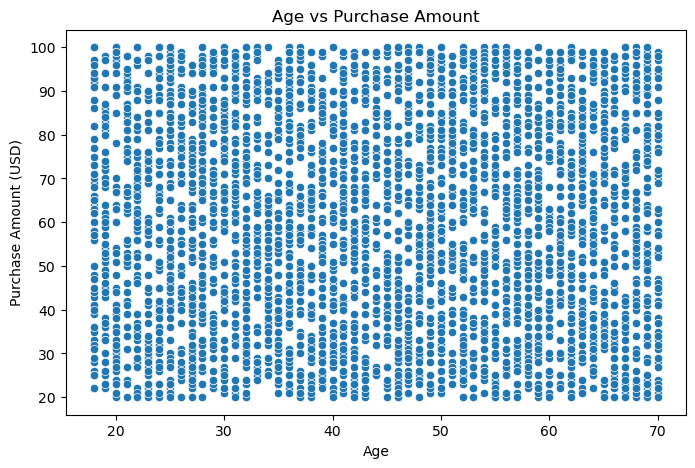

In [59]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Purchase Amount (USD)"
)

plt.title("Age vs Purchase Amount")
plt.xlabel("Age")
plt.ylabel("Purchase Amount (USD)")

plt.show()

In [60]:
# Key Business Insights

## 1. Product Categories
Clothing is the most important product category based on total purchase value.
Accessories are the second-largest category.

## 2. Seasonal Behavior
Customer purchases are fairly balanced across the four seasons.
Fall has the highest total purchase value.

## 3. Customer Spending
The average purchase amount is relatively consistent across product categories.

## 4. Customer Age
Age has almost no relationship with purchase amount.
Customers from different age groups show similar spending behavior.

## 5. Payment Methods
Customers use multiple payment methods, with some methods being more popular than others.

## 6. Discounts
Discount usage can be compared with purchase amounts to understand whether promotions influence customer spending.

## 7. Subscription
Subscription status can help identify whether subscribed customers have different spending behavior.

## 8. Purchase Frequency
Purchase frequency helps identify how often customers return to shop.

## 9. Customer Satisfaction
Review ratings help measure customer satisfaction and identify categories with relatively higher or lower ratings.

## 10. Shipping
Shipping preferences show which delivery options customers prefer.

SyntaxError: invalid syntax (2531757478.py, line 4)

In [61]:
# Key Business Insights

## 1. Product Categories
Clothing is the most important product category based on total purchase value.
Accessories are the second-largest category.

## 2. Seasonal Behavior
Customer purchases are fairly balanced across the four seasons.
Fall has the highest total purchase value.

## 3. Customer Spending
The average purchase amount is relatively consistent across product categories.

## 4. Customer Age
Age has almost no relationship with purchase amount.
Customers from different age groups show similar spending behavior.

## 5. Payment Methods
Customers use multiple payment methods, with some methods being more popular than others.

## 6. Discounts
Discount usage can be compared with purchase amounts to understand whether promotions influence customer spending.

## 7. Subscription
Subscription status can help identify whether subscribed customers have different spending behavior.

## 8. Purchase Frequency
Purchase frequency helps identify how often customers return to shop.

## 9. Customer Satisfaction
Review ratings help measure customer satisfaction and identify categories with relatively higher or lower ratings.

## 10. Shipping
Shipping preferences show which delivery options customers prefer.

SyntaxError: invalid syntax (2531757478.py, line 4)

In [62]:
# Key Business Insights

## 1. Product Categories
Clothing is the most important product category based on total purchase value.
Accessories are the second-largest category.

## 2. Seasonal Behavior
Customer purchases are fairly balanced across the four seasons.
Fall has the highest total purchase value.

## 3. Customer Spending
The average purchase amount is relatively consistent across product categories.

## 4. Customer Age
Age has almost no relationship with purchase amount.
Customers from different age groups show similar spending behavior.

## 5. Payment Methods
Customers use multiple payment methods, with some methods being more popular than others.

## 6. Discounts
Discount usage can be compared with purchase amounts to understand whether promotions influence customer spending.

## 7. Subscription
Subscription status can help identify whether subscribed customers have different spending behavior.

## 8. Purchase Frequency
Purchase frequency helps identify how often customers return to shop.

## 9. Customer Satisfaction
Review ratings help measure customer satisfaction and identify categories with relatively higher or lower ratings.

## 10. Shipping
Shipping preferences show which delivery options customers prefer.

SyntaxError: invalid syntax (2531757478.py, line 4)

In [63]:
print("KEY BUSINESS INSIGHTS")
print("---------------------")
print("1. Clothing is the leading product category.")
print("2. Fall has the highest total purchase value.")
print("3. Customer spending is relatively consistent across categories.")
print("4. Age has almost no relationship with purchase amount.")
print("5. Review ratings help measure customer satisfaction.")
print("6. Payment and shipping methods show customer preferences.")

KEY BUSINESS INSIGHTS
---------------------
1. Clothing is the leading product category.
2. Fall has the highest total purchase value.
3. Customer spending is relatively consistent across categories.
4. Age has almost no relationship with purchase amount.
5. Review ratings help measure customer satisfaction.
6. Payment and shipping methods show customer preferences.


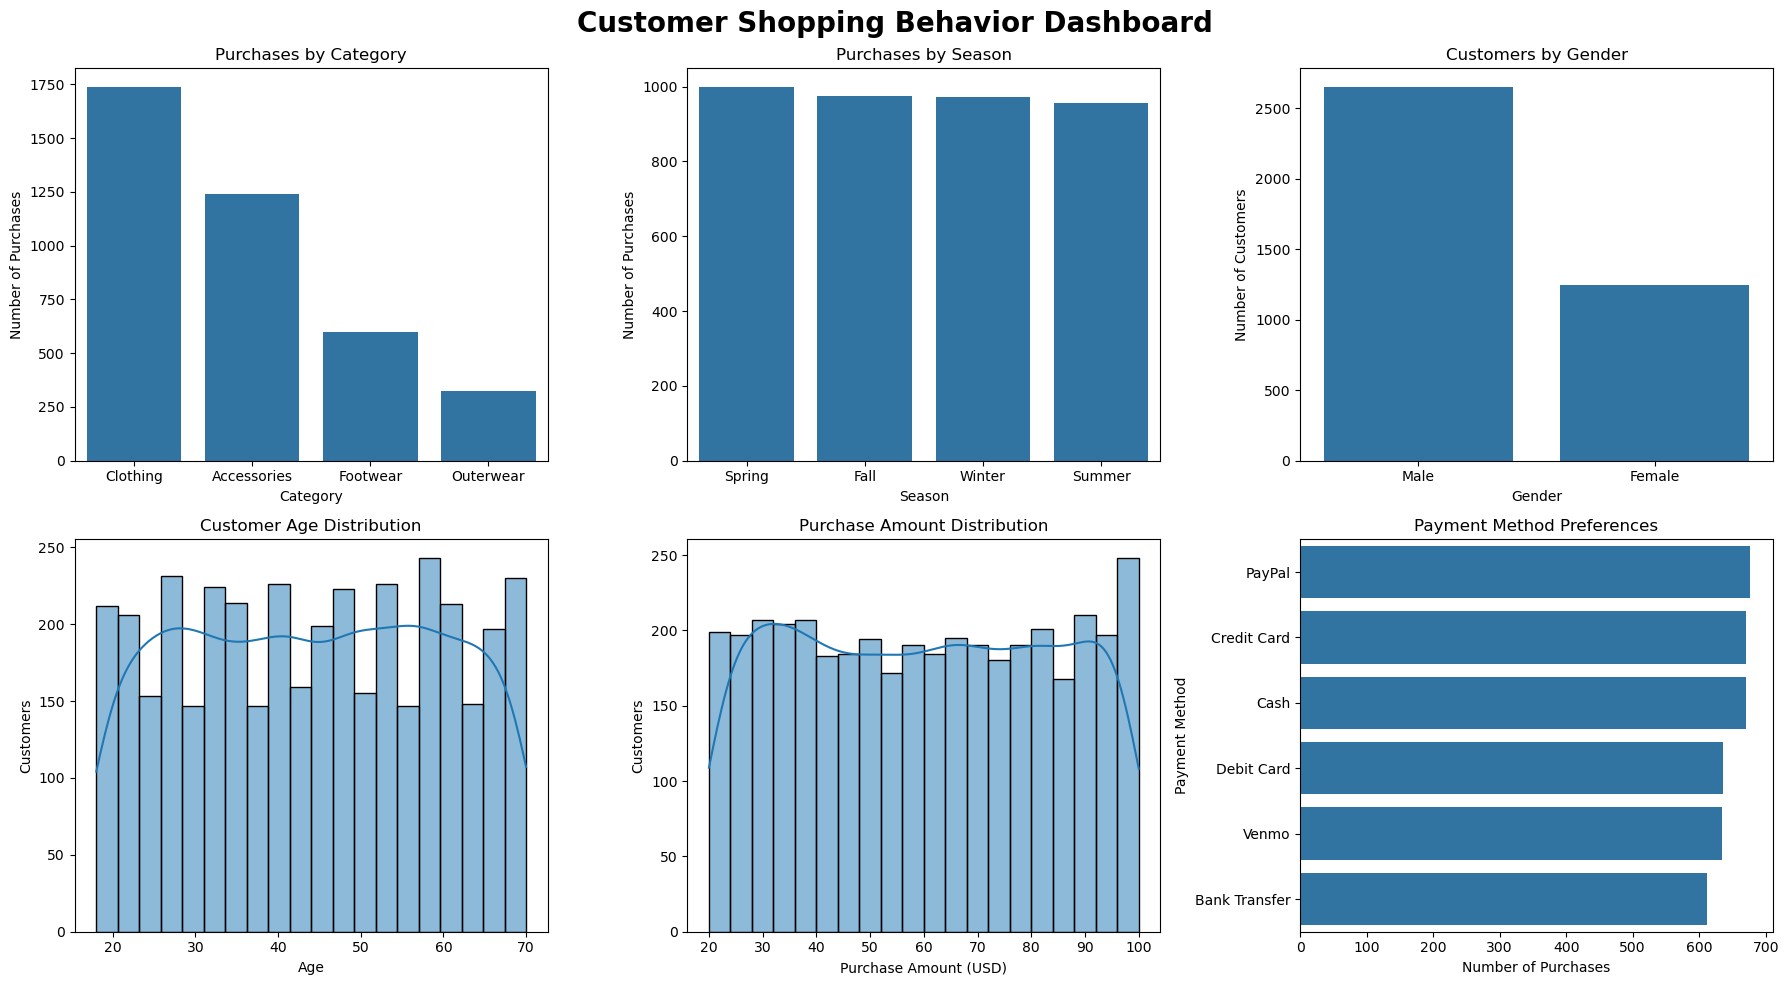

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create dashboard
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Category
sns.countplot(
    data=df,
    x="Category",
    order=df["Category"].value_counts().index,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Purchases by Category")
axes[0, 0].set_xlabel("Category")
axes[0, 0].set_ylabel("Number of Purchases")

# 2. Season
sns.countplot(
    data=df,
    x="Season",
    order=df["Season"].value_counts().index,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Purchases by Season")
axes[0, 1].set_xlabel("Season")
axes[0, 1].set_ylabel("Number of Purchases")

# 3. Gender
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[0, 2]
)
axes[0, 2].set_title("Customers by Gender")
axes[0, 2].set_xlabel("Gender")
axes[0, 2].set_ylabel("Number of Customers")

# 4. Age distribution
sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Customer Age Distribution")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Customers")

# 5. Purchase amount
sns.histplot(
    data=df,
    x="Purchase Amount (USD)",
    bins=20,
    kde=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Purchase Amount Distribution")
axes[1, 1].set_xlabel("Purchase Amount (USD)")
axes[1, 1].set_ylabel("Customers")

# 6. Payment method
payment_counts = df["Payment Method"].value_counts()

sns.barplot(
    x=payment_counts.values,
    y=payment_counts.index,
    ax=axes[1, 2]
)
axes[1, 2].set_title("Payment Method Preferences")
axes[1, 2].set_xlabel("Number of Purchases")
axes[1, 2].set_ylabel("Payment Method")

plt.suptitle(
    "Customer Shopping Behavior Dashboard",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout()
plt.show()